# **Sesión 2:** Calibración de Cámara 📷⚙️

## 0. Preparación

In [1]:
import cv2
print("OpenCV should be 4.8.x Current version:", cv2.__version__)
from typing import List
import numpy as np
# import imageio --- IGNORE IF DEPRECATED---
import imageio.v3 as imageio
import copy
import os
import glob

OpenCV should be 4.8.x Current version: 4.14.0


## **Apartado A: Calibración de cámara** (derecha e izquierda)

En este apartado se realiza la calibración de dos cámaras de un sistema estereoscópico. Para ello se trabajará con las imágenes de las carpetas ``left`` y ``right``. En primer lugar se trabajará con la carpeta ``left``. Posteriormente, deberá repetir el proceso con las imágenes en la carpeta ``right``. Ambas carpetas contienen imágenes con las que se calibrarán las cámaras. En ellas aparece el patrón de calibración en diferentes posiciones y orientaciones. Estas imágenes serán los datos de entrada.

Los pasos que deberá seguir para calibrar una cámara son:

1. Defina y ejecute el método para cargar imágenes ``load_images()``.
2. Detecte las esquinas de los patrones usando ``cv2.findChessboardCorners()``. Refine las detecciones con ``cv2.cornerSubPix()``.
3. Compruebe que las detecciones son correctas dibujando los resultados con ``cv2.drawChessboardCorners()``.
4. Defina y ejecute el método ``get_chessboard_points(chessboard_shape, dx, dy)`` que proporcione las coordenadas 3D de las esquinas del patrón. El sistema de referencia utilizado deberá estar anclado al propio patrón.
5. Utilice ``cv2.calibrateCamera`` para obtener los parámetros de calibración para la cámara izquierda.

### **Tarea A.1:** Defina y ejecute el método para cargar imágenes ``load_images()``.

In [78]:
def load_images(filenames: List) -> List:
    return [cv2.imread(filename) for filename in filenames]

In [79]:
# TODO Build a list containing the paths of all images from the left camera
new_path = "../data/left/left_"
imgs_path = []
i = 0
while i <= 18:
    str_i = str(i)
    if len(str_i) == 1:
        imgs_path.append(new_path + "00" + str_i + ".jpg")
    else:
        imgs_path.append(new_path + "0" + str_i + ".jpg")

    i += 1

imgs = load_images(imgs_path)

imgs_path

['../data/left/left_000.jpg',
 '../data/left/left_001.jpg',
 '../data/left/left_002.jpg',
 '../data/left/left_003.jpg',
 '../data/left/left_004.jpg',
 '../data/left/left_005.jpg',
 '../data/left/left_006.jpg',
 '../data/left/left_007.jpg',
 '../data/left/left_008.jpg',
 '../data/left/left_009.jpg',
 '../data/left/left_010.jpg',
 '../data/left/left_011.jpg',
 '../data/left/left_012.jpg',
 '../data/left/left_013.jpg',
 '../data/left/left_014.jpg',
 '../data/left/left_015.jpg',
 '../data/left/left_016.jpg',
 '../data/left/left_017.jpg',
 '../data/left/left_018.jpg']

### **Tarea A.2:** Detecte las esquinas de los patrones usando ``cv2.findChessboardCorners()``. Refine las detecciones con ``cv2.cornerSubPix()``.

In [80]:
# Study which winSize use
imgs[0].shape

(240, 320, 3)

In [81]:
# TODO Find corners with cv2.findChessboardCorners()
# Hint: you can use a list comprehension to process all images
corners = [cv2.findChessboardCorners(img, (8,6), None) for img in imgs]


In [82]:
corners_copy = copy.deepcopy(corners)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01)

# TODO To refine corner detections with cv2.cornerSubPix() you need to input grayscale images. Build a list containing grayscale images.
imgs_gray = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in imgs]
for i in range(len(imgs_gray)):
    ret, img_corners = corners_copy[i]
    
    # We refine only the images whose pattern has been find by openCV
    if ret == True:
        # cv2.cornerSubPix(imagen, esquinas, winSize, zeroZone, criteria)
        cv2.cornerSubPix(imgs_gray[i], img_corners, (5,5), (-1, -1), criteria)
    else:
        print(i)


### **Tarea A.3:** Compruebe que las detecciones son correctas dibujando los resultados con ``cv2.drawChessboardCorners()``

In [83]:
imgs_copy = copy.deepcopy(imgs)

In [84]:
# TODO Use cv2.drawChessboardCorners() to draw the cornes

for i in range(len(imgs_copy)):
    # We unpack the boolean and the coordinates (already refined)
    ret, img_corners = corners_copy[i]
    
    # Draw
    cv2.drawChessboardCorners(
        image=imgs_copy[i],
        patternSize= (8, 6),
        corners = img_corners,
        patternWasFound = ret )

In [85]:
# TODO Show images and save when needed

def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name, img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

def write_image(output_folder: str, img_name: str, img: np.array):
    img_path = os.path.join(output_folder, img_name)
    cv2.imwrite(img_path, img)

In [86]:
# Resize to watch better the images
for i in range(len(imgs_copy)):
    img = imgs_copy[i]
    img = cv2.resize(img, (850, 650))
    show_image(img)

### **Tarea A.4:** Defina y ejecute el método ``get_chessboard_points(chessboard_shape, dx, dy)``

In [87]:
# TODO Design the method. It should return a np.array with np.float32 elements
import numpy as np

def get_chessboard_points(chessboard_shape, dx, dy):
    cols, rows = chessboard_shape

    pts = np.zeros((rows * cols, 3), dtype=np.float32)
    pts[:, :2] = np.mgrid[0:cols, 0:rows].T.reshape(-1, 2) * (dx, dy)
    return pts
    

In [88]:
# TODO You need the points for every image, not just one (consider a list comprehension)
chessboard_shape = (8,6)
dx = dy = 30.0 # mms
chessboard_points = get_chessboard_points(chessboard_shape, dx, dy)

# I can print every imagen (ret=true) because every one achieve it
chessboard_points

array([[  0.,   0.,   0.],
       [ 30.,   0.,   0.],
       [ 60.,   0.,   0.],
       [ 90.,   0.,   0.],
       [120.,   0.,   0.],
       [150.,   0.,   0.],
       [180.,   0.,   0.],
       [210.,   0.,   0.],
       [  0.,  30.,   0.],
       [ 30.,  30.,   0.],
       [ 60.,  30.,   0.],
       [ 90.,  30.,   0.],
       [120.,  30.,   0.],
       [150.,  30.,   0.],
       [180.,  30.,   0.],
       [210.,  30.,   0.],
       [  0.,  60.,   0.],
       [ 30.,  60.,   0.],
       [ 60.,  60.,   0.],
       [ 90.,  60.,   0.],
       [120.,  60.,   0.],
       [150.,  60.,   0.],
       [180.,  60.,   0.],
       [210.,  60.,   0.],
       [  0.,  90.,   0.],
       [ 30.,  90.,   0.],
       [ 60.,  90.,   0.],
       [ 90.,  90.,   0.],
       [120.,  90.,   0.],
       [150.,  90.,   0.],
       [180.,  90.,   0.],
       [210.,  90.,   0.],
       [  0., 120.,   0.],
       [ 30., 120.,   0.],
       [ 60., 120.,   0.],
       [ 90., 120.,   0.],
       [120., 120.,   0.],
 

In [89]:
chessboard_points.shape

(48, 3)

### **Tarea A.5:** Utilice ``cv2.calibrateCamera()`` para obtener los parámetros de calibración para la cámara izquierda

In [90]:
# Filter data and get only those with adequate detections
# Convert list to numpy array with np.float32 elements
valid_corners = [corners.astype(np.float32) for ret, corners in corners_copy if ret]
len(valid_corners)

19

In [ ]:
# TODO
img_size = imgs_gray[0].shape[::-1] # (width, height) = (320, 240)

object_points = [chessboard_points for _ in valid_corners]

rms, intrinsics, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(
    object_points,
    valid_corners,
    img_size,
    None,
    None
)

# Obtain extrinsics
extrinsics = list(map(lambda rvec, tvec: np.hstack((cv2.Rodrigues(rvec)[0], tvec)), rvecs, tvecs))

In [92]:
print("Extrinsics:",extrinsics)

Extrinsics: [array([[ 7.23876634e-01,  6.10200379e-01, -3.21959805e-01,
        -2.28428219e+01],
       [-1.72429433e-01,  6.11854146e-01,  7.71947275e-01,
        -3.02099116e+01],
       [ 6.68034961e-01, -5.03279248e-01,  5.48123425e-01,
         5.22861142e+02]]), array([[ 7.28931594e-01,  5.93322392e-01, -3.41507351e-01,
        -4.94164867e+01],
       [-1.81438547e-01,  6.48449186e-01,  7.39319760e-01,
        -3.96315439e+01],
       [ 6.60105131e-01, -4.76950934e-01,  5.80326651e-01,
         5.13144434e+02]]), array([[ 7.37329635e-01,  5.76271394e-01, -3.52500058e-01,
        -6.05542899e+01],
       [-1.94138773e-01,  6.80559773e-01,  7.06504446e-01,
        -5.52941280e+01],
       [ 6.47035661e-01, -4.52492737e-01,  6.13673510e-01,
         5.04747009e+02]]), array([[ 7.59013925e-01,  5.51391472e-01, -3.46215693e-01,
        -5.45509948e+01],
       [-1.99484715e-01,  7.03136585e-01,  6.82498931e-01,
        -6.68071573e+01],
       [ 6.19761011e-01, -4.48961453e-01,  6.4

In [93]:
# Print outputs
print("Intrinsics:\n", intrinsics)
print("Distortion coefficients:\n", dist_coeffs)
print("Root mean squared reprojection error:\n", rms)

Intrinsics:
 [[421.4029491    0.         149.84371067]
 [  0.         421.93967438 128.36267339]
 [  0.           0.           1.        ]]
Distortion coefficients:
 [[-5.96159593e-02 -1.37997969e+00  4.48188397e-03 -6.78432101e-03
   7.00246239e+00]]
Root mean squared reprojection error:
 0.09356699327660309


### **Pregunta A.1:** Repita el proceso (carga de imágenes, detección y comprobación de esquinas, etc.) para la cámara derecha.

In [94]:
new_path_r = "../data/right/right_"
imgs_path_r = []
i = 0
while i <= 18:
    str_i = str(i)
    if len(str_i) == 1:
        imgs_path_r.append(new_path_r + "00" + str_i + ".jpg")
    else:
        imgs_path_r.append(new_path_r + "0" + str_i + ".jpg")

    i += 1

imgs_r = load_images(imgs_path_r)

imgs_path_r

['../data/right/right_000.jpg',
 '../data/right/right_001.jpg',
 '../data/right/right_002.jpg',
 '../data/right/right_003.jpg',
 '../data/right/right_004.jpg',
 '../data/right/right_005.jpg',
 '../data/right/right_006.jpg',
 '../data/right/right_007.jpg',
 '../data/right/right_008.jpg',
 '../data/right/right_009.jpg',
 '../data/right/right_010.jpg',
 '../data/right/right_011.jpg',
 '../data/right/right_012.jpg',
 '../data/right/right_013.jpg',
 '../data/right/right_014.jpg',
 '../data/right/right_015.jpg',
 '../data/right/right_016.jpg',
 '../data/right/right_017.jpg',
 '../data/right/right_018.jpg']

In [95]:
imgs[0].shape # same than left ones

(240, 320, 3)

In [96]:
corners_r = [cv2.findChessboardCorners(img, (8,6), None) for img in imgs_r]
corners_copy_r = copy.deepcopy(corners_r)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01)

# TODO To refine corner detections with cv2.cornerSubPix() you need to input grayscale images. Build a list containing grayscale images.
imgs_gray_r = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in imgs_r]
for i in range(len(imgs_gray_r)):
    ret, img_corners = corners_copy_r[i]
    
    # We refine only the images whose pattern has been find by openCV
    if ret == True:
        # cv2.cornerSubPix(imagen, esquinas, winSize, zeroZone, criteria)
        cv2.cornerSubPix(imgs_gray_r[i], img_corners, (5,5), (-1, -1), criteria)
    else:
        print(i)


1
14


In [97]:
imgs_copy_r = copy.deepcopy(imgs_r)
# TODO Use cv2.drawChessboardCorners() to draw the cornes

for i in range(len(imgs_copy_r)):
    # We unpack the boolean and the coordinates (already refined)
    ret, img_corners = corners_copy_r[i]
    
    # Draw
    cv2.drawChessboardCorners(
        image=imgs_copy_r[i],
        patternSize= (8, 6),
        corners = img_corners,
        patternWasFound = ret )

In [98]:
# Resize to watch better the images
for i in range(len(imgs_copy_r)):
    img = imgs_copy_r[i]
    img = cv2.resize(img, (850, 650))
    show_image(img)

In [99]:
# TODO You need the points for every image, not just one (consider a list comprehension)
chessboard_shape = (8,6)
dx = dy = 30.0 # mms

# Reutilize as they are the sames
chessboard_points_r = chessboard_points

In [ ]:
valid_corners_r = [corners.astype(np.float32) for ret, corners in corners_copy_r if ret]
# TODO
img_size_r = imgs_gray_r[0].shape[::-1] # (width, height) = (320, 240)

object_points_r = [chessboard_points_r for _ in valid_corners_r]

rms, intrinsics, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(
    object_points_r,
    valid_corners_r,
    img_size_r,
    None,
    None
)

# Obtain extrinsics
extrinsics = list(map(lambda rvec, tvec: np.hstack((cv2.Rodrigues(rvec)[0], tvec)), rvecs, tvecs))

In [101]:
print("Extrinsics:",extrinsics)

Extrinsics: [array([[ 7.17899529e-01,  6.12702533e-01, -3.30478248e-01,
        -8.91481830e+01],
       [-1.78661877e-01,  6.20984527e-01,  7.63189459e-01,
        -3.75076871e+01],
       [ 6.72829994e-01, -4.88849489e-01,  5.55271084e-01,
         5.22205695e+02]]), array([[ 7.30106285e-01,  5.80558165e-01, -3.60412305e-01,
        -1.26994086e+02],
       [-1.99449382e-01,  6.85516019e-01,  7.00205492e-01,
        -6.22617526e+01],
       [ 6.53578424e-01, -4.39340419e-01,  6.16291521e-01,
         5.02769049e+02]]), array([[ 7.51478225e-01,  5.54658122e-01, -3.57260192e-01,
        -1.20026934e+02],
       [-2.03321695e-01,  7.09842353e-01,  6.74376840e-01,
        -7.30090212e+01],
       [ 6.27647007e-01, -4.34140763e-01,  6.46205101e-01,
         5.02653865e+02]]), array([[ 7.67487030e-01,  5.37340536e-01, -3.49612365e-01,
        -1.18809665e+02],
       [-2.01714426e-01,  7.20081459e-01,  6.63923175e-01,
        -7.82973777e+01],
       [ 6.08502217e-01, -4.39030568e-01,  6.6

In [102]:
# Print outputs
print("Intrinsics:\n", intrinsics)
print("Distortion coefficients:\n", dist_coeffs)
print("Root mean squared reprojection error:\n", rms)

Intrinsics:
 [[428.31880629   0.         144.67973458]
 [  0.         429.52254569 138.23357671]
 [  0.           0.           1.        ]]
Distortion coefficients:
 [[-0.10833263 -0.28795845  0.00628941 -0.0053366   1.88194141]]
Root mean squared reprojection error:
 0.0979414754217794


### **Pregunta A.2:** Diferencias entre cv2.findChessboardCorners() y cv2.cornerSubPix()

In [103]:
idx_img = 10
idx_corner = 10

corner_raw = corners[idx_img][1][idx_corner][0]           # find
corner_refined = corners_copy[idx_img][1][idx_corner][0]  # subPix

print("Antes:", corner_raw, " Después:", corner_refined, 
      " Desplazamiento:", corner_refined - corner_raw)

def crop_around(img, point, size=40):
    x, y = int(point[0]), int(point[1])
    return img[max(0,y-size):y+size, max(0,x-size):x+size]

img_before = imgs[idx_img].copy()
cv2.circle(img_before, tuple(corner_raw.astype(int)), 2, (0,0,255), -1)

img_after = imgs[idx_img].copy()
cv2.circle(img_after, tuple(corner_refined.astype(int)), 2, (0,255,0), -1)

crop_before = crop_around(img_before, corner_raw)
crop_after = crop_around(img_after, corner_refined)

crop_before = cv2.resize(crop_before, None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST)
crop_after = cv2.resize(crop_after, None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST)

cv2.putText(crop_before, "Antes (find)", (5, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,0,255), 1)
cv2.putText(crop_after, "Despues (subPix)", (5, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 1)

comparison = np.hstack([crop_before, crop_after])

show_image(comparison, "Antes vs Despues")

Antes: [130.77782  72.89382]  Después: [130.7609   72.84477]  Desplazamiento: [-0.016922   -0.04904938]


### **Pregunta A.3:** Número mínimo de imágenes necesarias para calibrar.

Imágenes válidas disponibles: 19


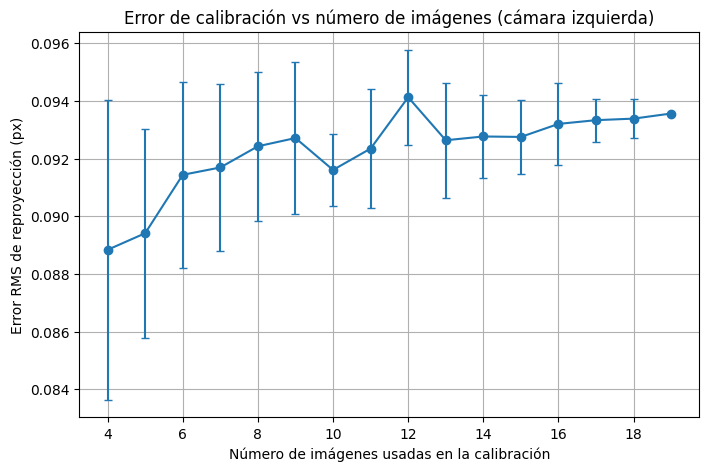

In [ ]:
# TODO Homework
import random
import matplotlib.pyplot as plt

# left images
valid_corners = [corners.astype(np.float32) for ret, corners in corners_copy if ret]
n_total = len(valid_corners)
print("Imágenes válidas disponibles:", n_total)

n_repeats = 15 # repetitions for each subset size, to average
min_images = 4 # cv2.calibrateCamera needs at least a few views
sizes = list(range(min_images, n_total + 1))

mean_rms = []
std_rms = []

for n in sizes:
    errors = []
    for _ in range(n_repeats):
        idxs = random.sample(range(n_total), n)
        obj_pts = [chessboard_points for _ in idxs]
        img_pts = [valid_corners[i] for i in idxs]

        try:
            rms_n, _, _, _, _ = cv2.calibrateCamera(
                obj_pts, img_pts, img_size, None, None
            )
            errors.append(rms_n)
        except cv2.error:
            # Some combination might fail if the views are not very varied
            continue

    mean_rms.append(np.mean(errors))
    std_rms.append(np.std(errors))

plt.figure(figsize=(8,5))
plt.errorbar(sizes, mean_rms, yerr=std_rms, marker='o', capsize=3)
plt.xlabel("Número de imágenes usadas en la calibración")
plt.ylabel("Error RMS de reproyección (px)")
plt.title("Error de calibración vs número de imágenes (cámara izquierda)")
plt.grid(True)
plt.show()

## **Apartado B: Corrección de distorsión** (ojo de pez)

En este apartado se trabajará en la corrección de la distorsión debido a lentes de ojo de pez. Primero se calibrará una cámara con este tipo de lente, utilizando las imágenes de la carpeta ``fisheye``. Posteriormente se utilizarán estos parámetros de calibración para corregir la distorsión de una de las imágenes de calibración.

Los pasos que deberá seguir para calibrar una cámara con distorsión de ojo de pez son:

1. Reutilice el método ``load_images()`` para cargar las imágenes de la carpeta ``fisheye``.
2. Detecte las equinas procesando las imágenes con los métodos ``cv2.findChessboardCorners()`` y ``cv2.cornerSubPix()``.
3. Reutilice la función ``get_chessboard_points()`` para obtener las coordenadas del tablero.
4. Defina los argumentos para la función de calibración.
5. Calibre con ``cv2.fisheye.calibrate()``

### **Tarea B.1:** Reutilice el método ``load_images()`` para cargar las imágenes de la carpeta ``fisheye``

In [105]:
# TODO Build a list containing the paths of all images from the fisheye camera and load images
fisheye_imgs_path = [load_images()]
fisheye_imgs = load_images()

TypeError: load_images() missing 1 required positional argument: 'filenames'

### **Tarea B.2:** Detecte las equinas procesando las imágenes con los métodos ``cv2.findChessboardCorners()`` y ``cv2.cornerSubPix()``.

In [ ]:
imgs_corners = []
# Parameters for cv2.cornerSubPix()
subpix_criteria = (cv2.TERM_CRITERIA_EPS+cv2.TERM_CRITERIA_MAX_ITER, 30, 0.1)

#TODO Complete the required parts of the loop
for img in fisheye_imgs:
    
    # TODO parse arguments to cv2.findChessboardCorners()
    corners = cv2.findChessboardCorners()
    
    # TODO convert image to grayscale to use cv2.cornerSubPix()
    gray_img = cv2.cvtColor()
    refined_corners = cv2.cornerSubPix(gray_img, corners, (3,3), (-1,-1), subpix_criteria)

    # TODO append only those refined_corners with proper detections
    imgs_corners.append(refined_corners)

### **Tarea B.3:** Reutilice la función ``get_chessboard_points()`` para obtener las coordenadas del tablero

In [ ]:
# TODO Define the chessboard dimensions and the lenght of the squares (in [mm])
chessboard_dims = (None, None)
length = None
# TODO You need the points for every image, not just one (consider a list comprehension)
fisheye_chessboard_points = get_chessboard_points(chessboard_dims, length, length)

### **Tarea B.4:** Defina los argumentos para la calibración

In [ ]:
# Parameters for cv2.fisheye.calibrate()
calibration_flags = cv2.fisheye.CALIB_RECOMPUTE_EXTRINSIC+cv2.fisheye.CALIB_FIX_SKEW
intrinsics = np.zeros((3, 3))
distortion = np.zeros((4, 1))
rotations = [np.zeros((1, 1, 3), dtype=np.float64) for _ in imgs_corners]
traslations = [np.zeros((1, 1, 3), dtype=np.float64) for _ in imgs_corners]


### **Tarea B.5:** Calibración

In [ ]:
rms, _, _, _, _ = \
cv2.fisheye.calibrate(fisheye_chessboard_points, imgs_corners, gray_img.shape[::-1], intrinsics, distortion, rotations, traslations, calibration_flags, subpix_criteria)

In [ ]:
# Show intrinsic matrix and distortion coefficients values
print(intrinsics)
print(distortion)
print(rms)

### **Pregunta B.1:** Corrija la distorsión de las 2 primeras imágenes de la carpeta ``fisheye``

In [ ]:
# TODO Search in the documentation to define 'dim'
dim = None
map1, map2 = cv2.fisheye.initUndistortRectifyMap(intrinsics, distortion, np.eye(3), intrinsics, dim, cv2.CV_16SC2)

In [ ]:
# TODO Homework: correct distortion using cv2.remap()